# PathSnap — Phase 1: Dataset Exploration & Feature Engineering (Member 1)

This notebook covers Member 1's pre-lunch deliverables:
1. Raw dataset inspection across **80 `train` trips** and **10 `student_test` trips** (`evaluator_test` kept completely untouched).
2. Data-quality checks (missing values, 1 Hz timestamps, GPS gaps, road-network connectivity, and high-offset anomalies).
3. Coordinate projection to local meters, monotonic DP alignment between `.track` and `.route`, and interactive Folium maps.
4. KDTree candidate generation (`K=10`), 16 spatial/kinematic features, and leakage-free `StandardScaler` fit strictly on `train`.

In [1]:
import os
import sys
import json
import joblib
import numpy as np
import pandas as pd
from IPython.display import display, Image

REPO_ROOT = os.path.abspath("..")
sys.path.insert(0, REPO_ROOT)
from src.data.data_loader import load_trip, project_to_local_meters, align_track_to_route

print("Repository root:", REPO_ROOT)

Repository root: d:\university\sem 5\ML\ML LAB\ML Hackathon


## 1. Dataset Inventory & Data Quality Summary
Tables generated by `src/data/eda_analysis.py` across all 90 available trips.

In [2]:
inv_df = pd.read_csv(os.path.join(REPO_ROOT, "outputs", "eda", "tables", "dataset_inventory.csv"))
dq_df = pd.read_csv(os.path.join(REPO_ROOT, "outputs", "eda", "tables", "data_quality_report.csv"))
trips_df = pd.read_csv(os.path.join(REPO_ROOT, "outputs", "eda", "tables", "trip_level_stats.csv"))

print("--- Dataset Inventory ---")
display(inv_df)
print("--- Data Quality Report ---")
display(dq_df)

--- Dataset Inventory ---


,partition,n_trips,total_files,total_gps_points,mean_gps_per_trip,min_gps_per_trip,max_gps_per_trip,total_nodes,total_arcs,total_route_arcs,median_noise_dist_m,p95_noise_dist_m
0,train,80,320,208417,2605.2,361,19313,1933485,3876904,31336,5.67,141.23
1,student_test,10,40,19160,1916.0,262,3958,90689,185041,3477,5.25,16.80


--- Data Quality Report ---


,partition,missing_or_nan_values,non_monotonic_timestamps,pct_steps_exactly_1s,steps_gt_2s,steps_gt_5s,max_single_gap_s,total_isolated_nodes,trips_with_multi_components,disconnected_route_transitions,trips_with_median_offset_gt_30m
0,train,0,0,96.50,2937,1216,153064.0,0,79,13,2
1,student_test,0,0,98.62,138,44,210.0,0,10,1,0


## 2. Inspecting Trip File Structure & Anomaly Trips
Notice that `.track` rows (1 Hz GPS points) do not correspond 1-to-1 with `.route` rows (traversed `arc_id` sequence). Also notice trips `00000033` and `00000054` in `train` exhibit >120 m median GPS-to-route offset.

In [3]:
sample = load_trip(os.path.join(REPO_ROOT, "data", "raw"), "student_test", "00000000")
print(f"Sample student_test/00000000 -> track: {sample['track'].shape}, nodes: {sample['nodes'].shape}, arcs: {sample['arcs'].shape}, route: {sample['route'].shape}")

print("\nTop 5 trips by median GPS-to-route offset (m):")
display(trips_df.sort_values("median_gps_to_route_dist_m", ascending=False).head(5))

Sample student_test/00000000 -> track: (2503, 3), nodes: (8542, 2), arcs: (18196, 2), route: (179,)

Top 5 trips by median GPS-to-route offset (m):


,partition,trip_id,n_gps_points,duration_sec,n_nodes,n_arcs,n_route_arcs,mean_lon,mean_lat,bbox_width_km,...,missing_values,non_monotonic_steps,pct_exact_1s_dt,n_gaps_gt_5s,max_dt_gap_s,isolated_nodes,n_connected_components,disconnected_route_transitions,median_gps_to_route_dist_m,p95_gps_to_route_dist_m
44,train,54,19313,19523.0,63822,116916,422,4.85530,52.29379,8.626,...,0,0,99.84,6,79.0,0,213,0,139.22,209.28
26,train,33,5844,6252.0,3340,6360,169,18.69883,50.03186,1.707,...,0,0,93.03,0,3.0,0,7,1,121.66,141.19
35,train,43,2322,2642.0,109070,215620,427,4.98693,52.13953,16.729,...,0,0,99.78,3,230.0,0,421,0,11.00,70.04
3,train,4,1064,5217.0,7350,15499,320,12.42422,52.64150,7.926,...,0,0,53.81,320,51.0,0,12,0,8.53,29.38
6,train,8,3093,3093.0,4995,10421,173,-86.57655,34.74533,1.589,...,0,0,99.97,0,2.0,0,13,0,7.77,28.15


## 3. Exploratory Plots & Folium Maps

Plot: 01_trip_length_and_duration.png


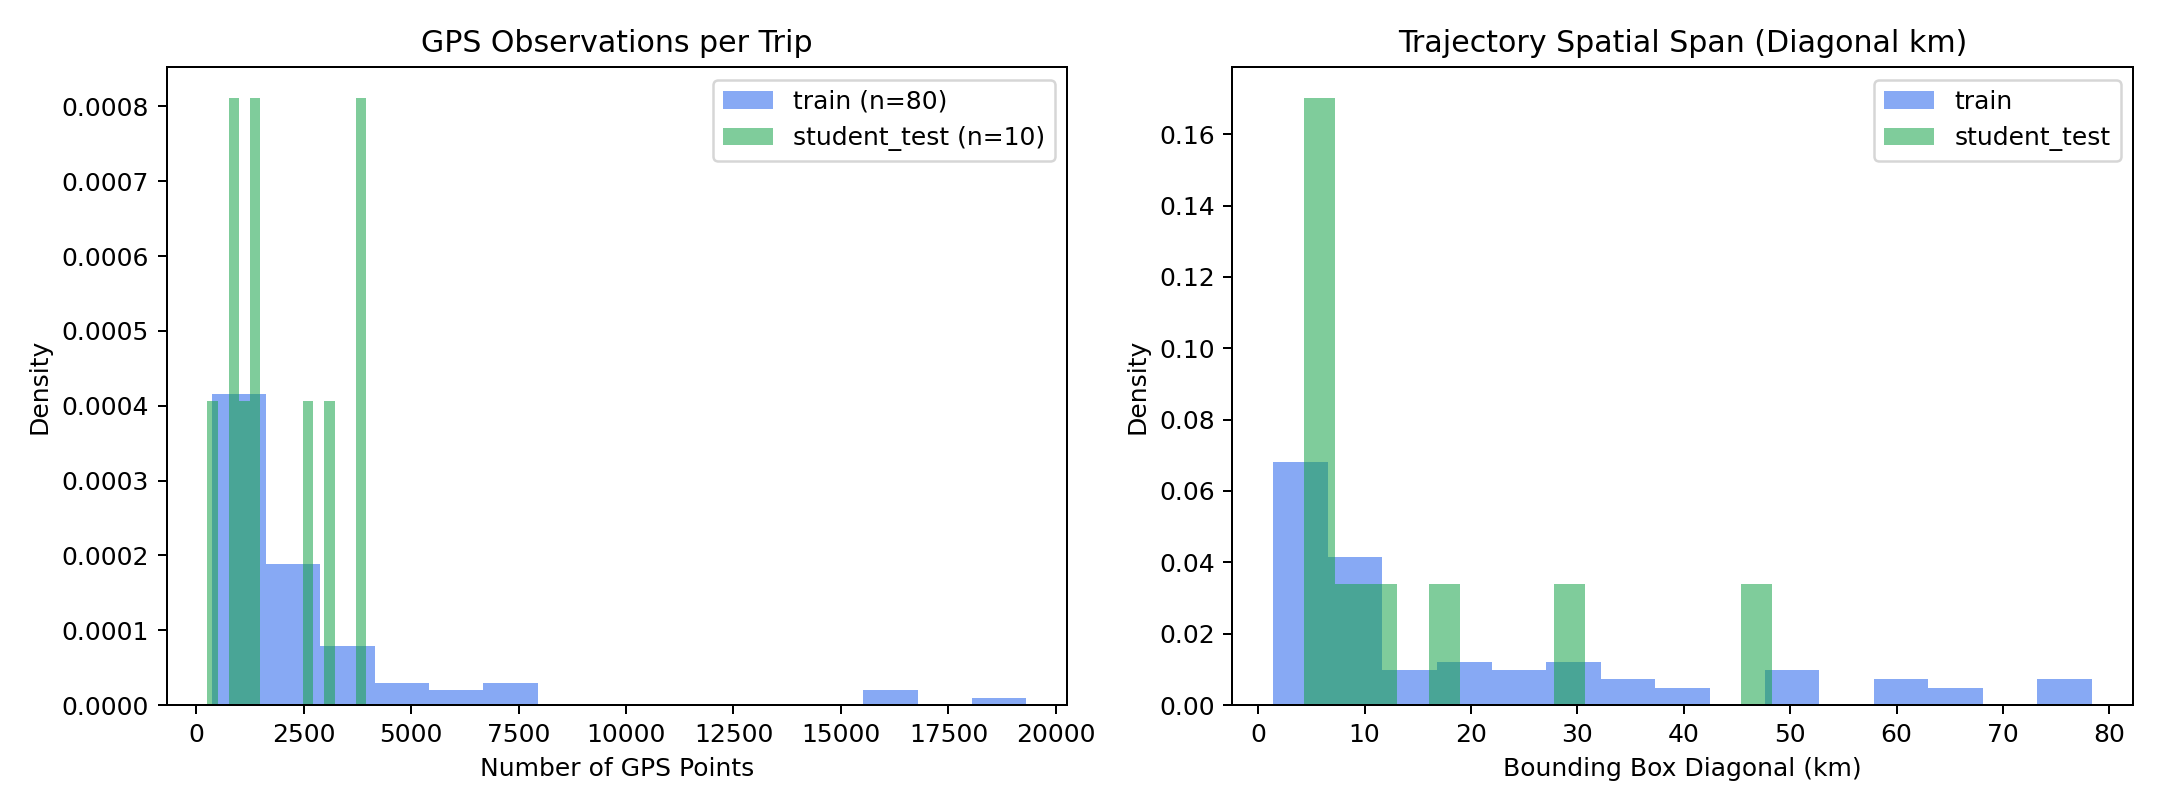

Plot: 02_sampling_intervals_and_gaps.png


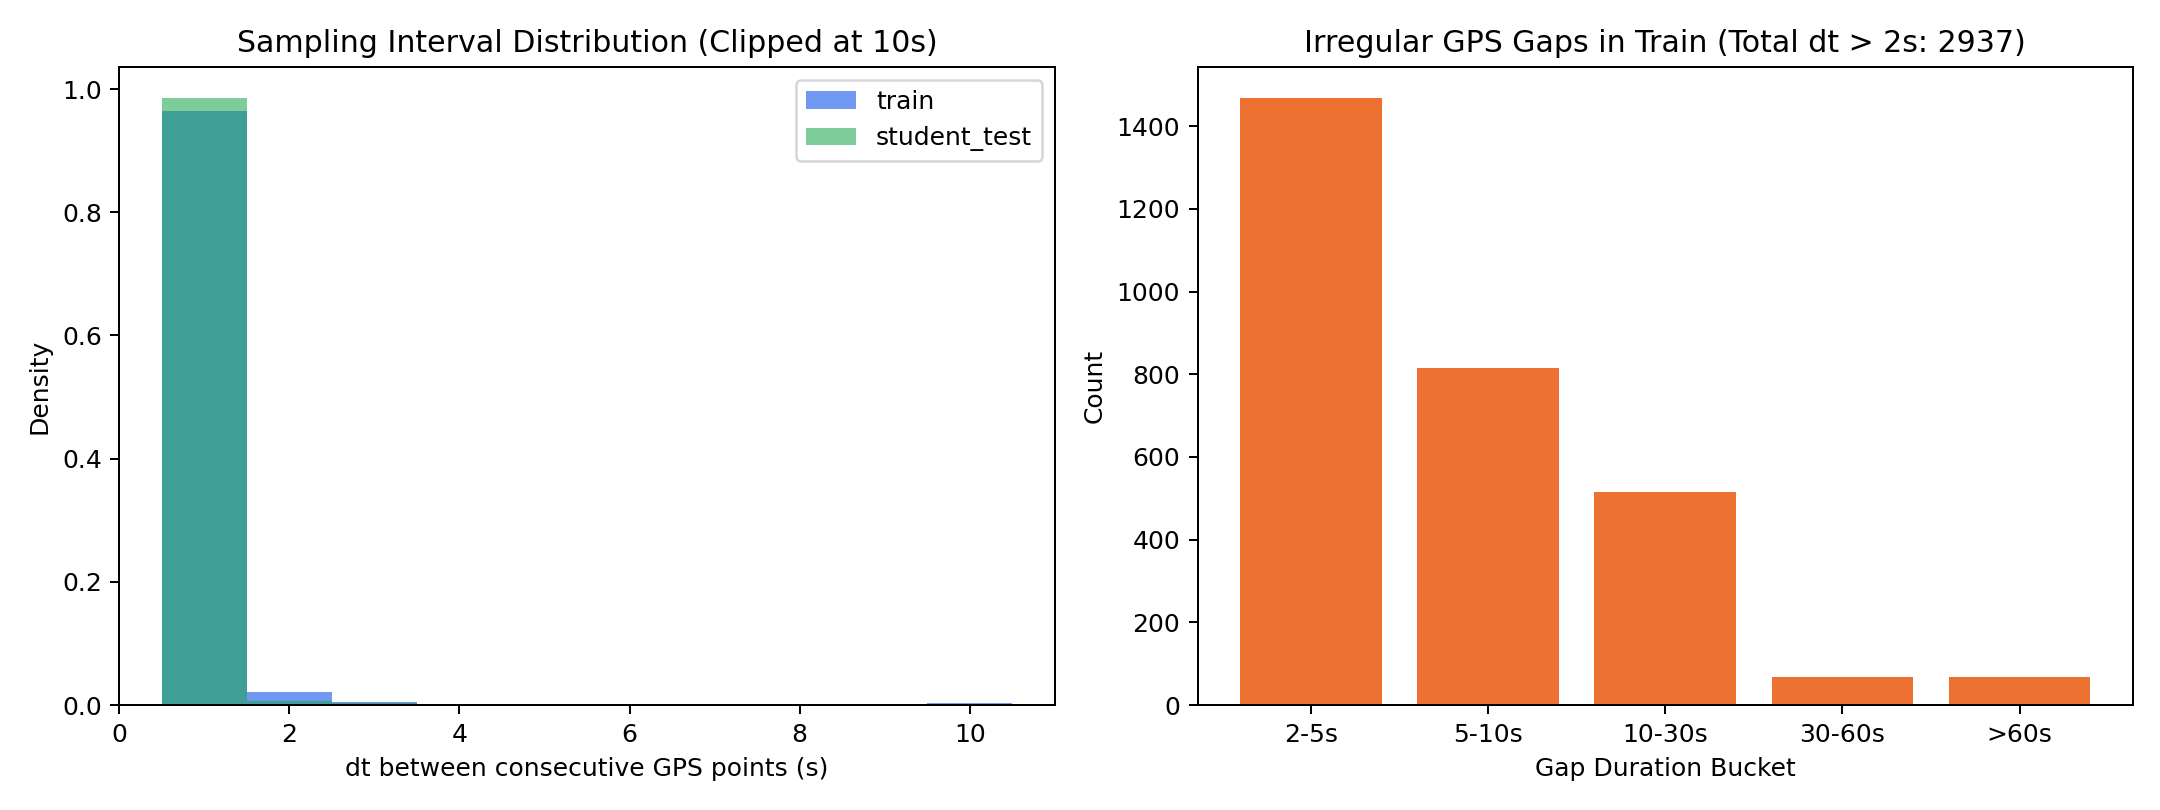

Plot: 03_road_network_and_gps_noise.png


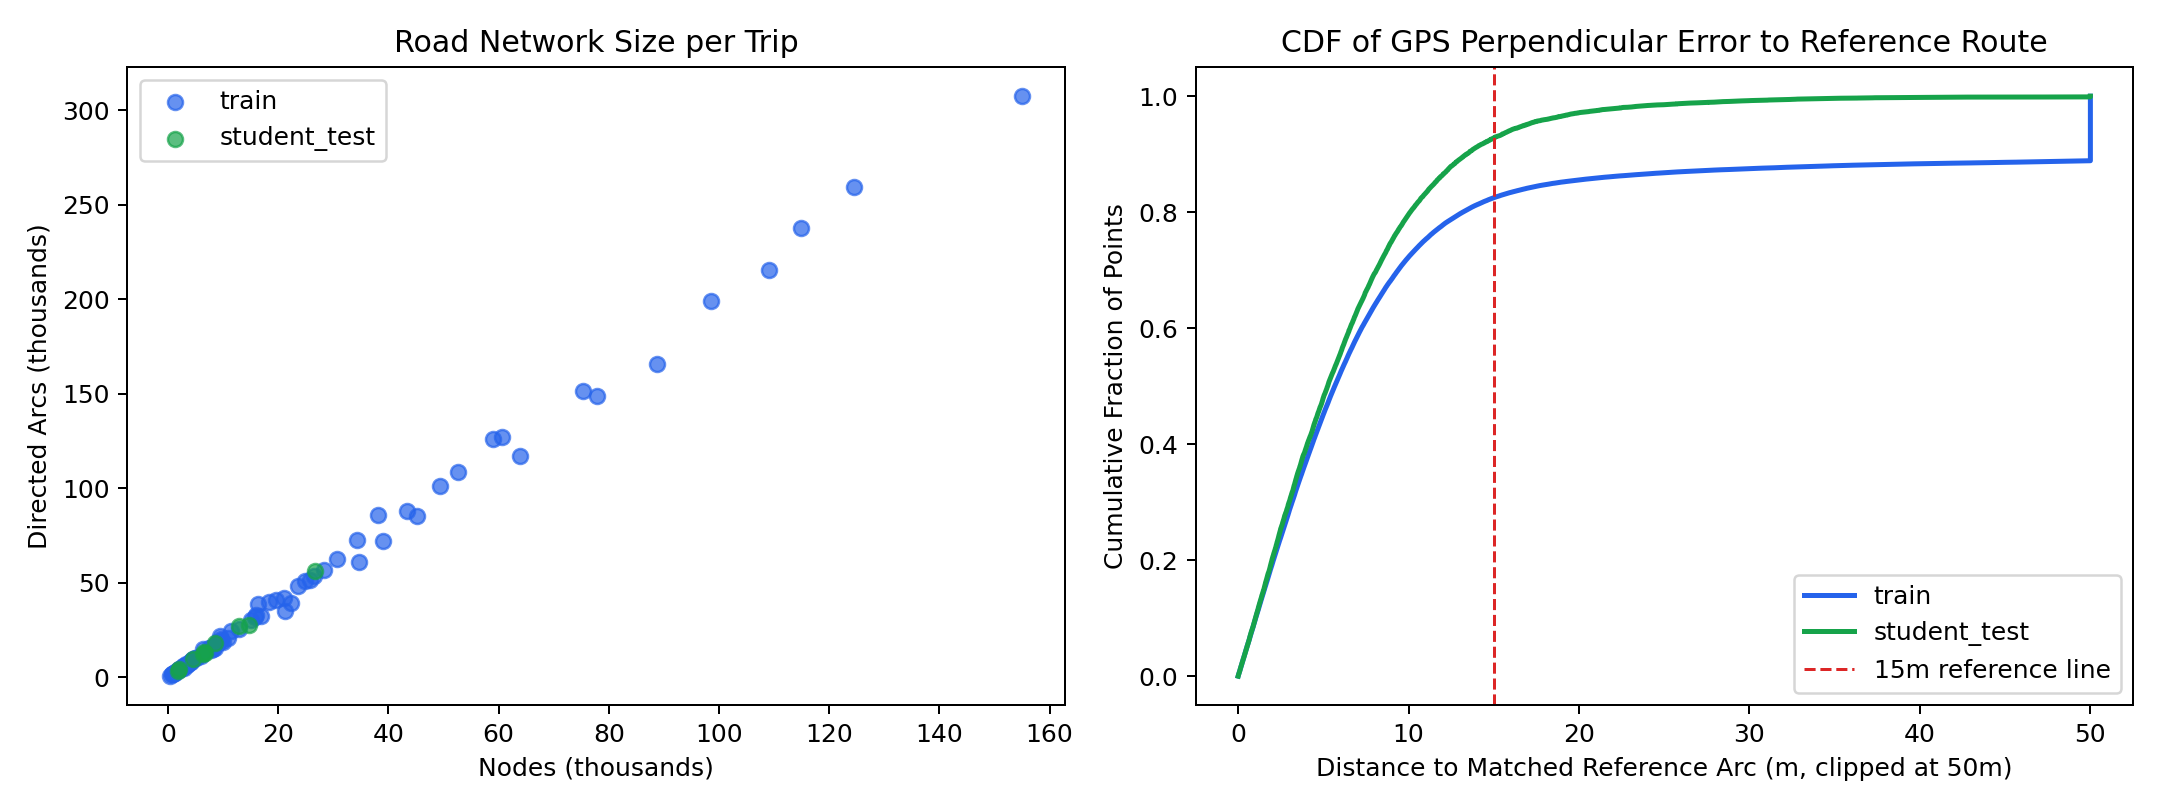

Plot: 04_sample_trips_overlay.png


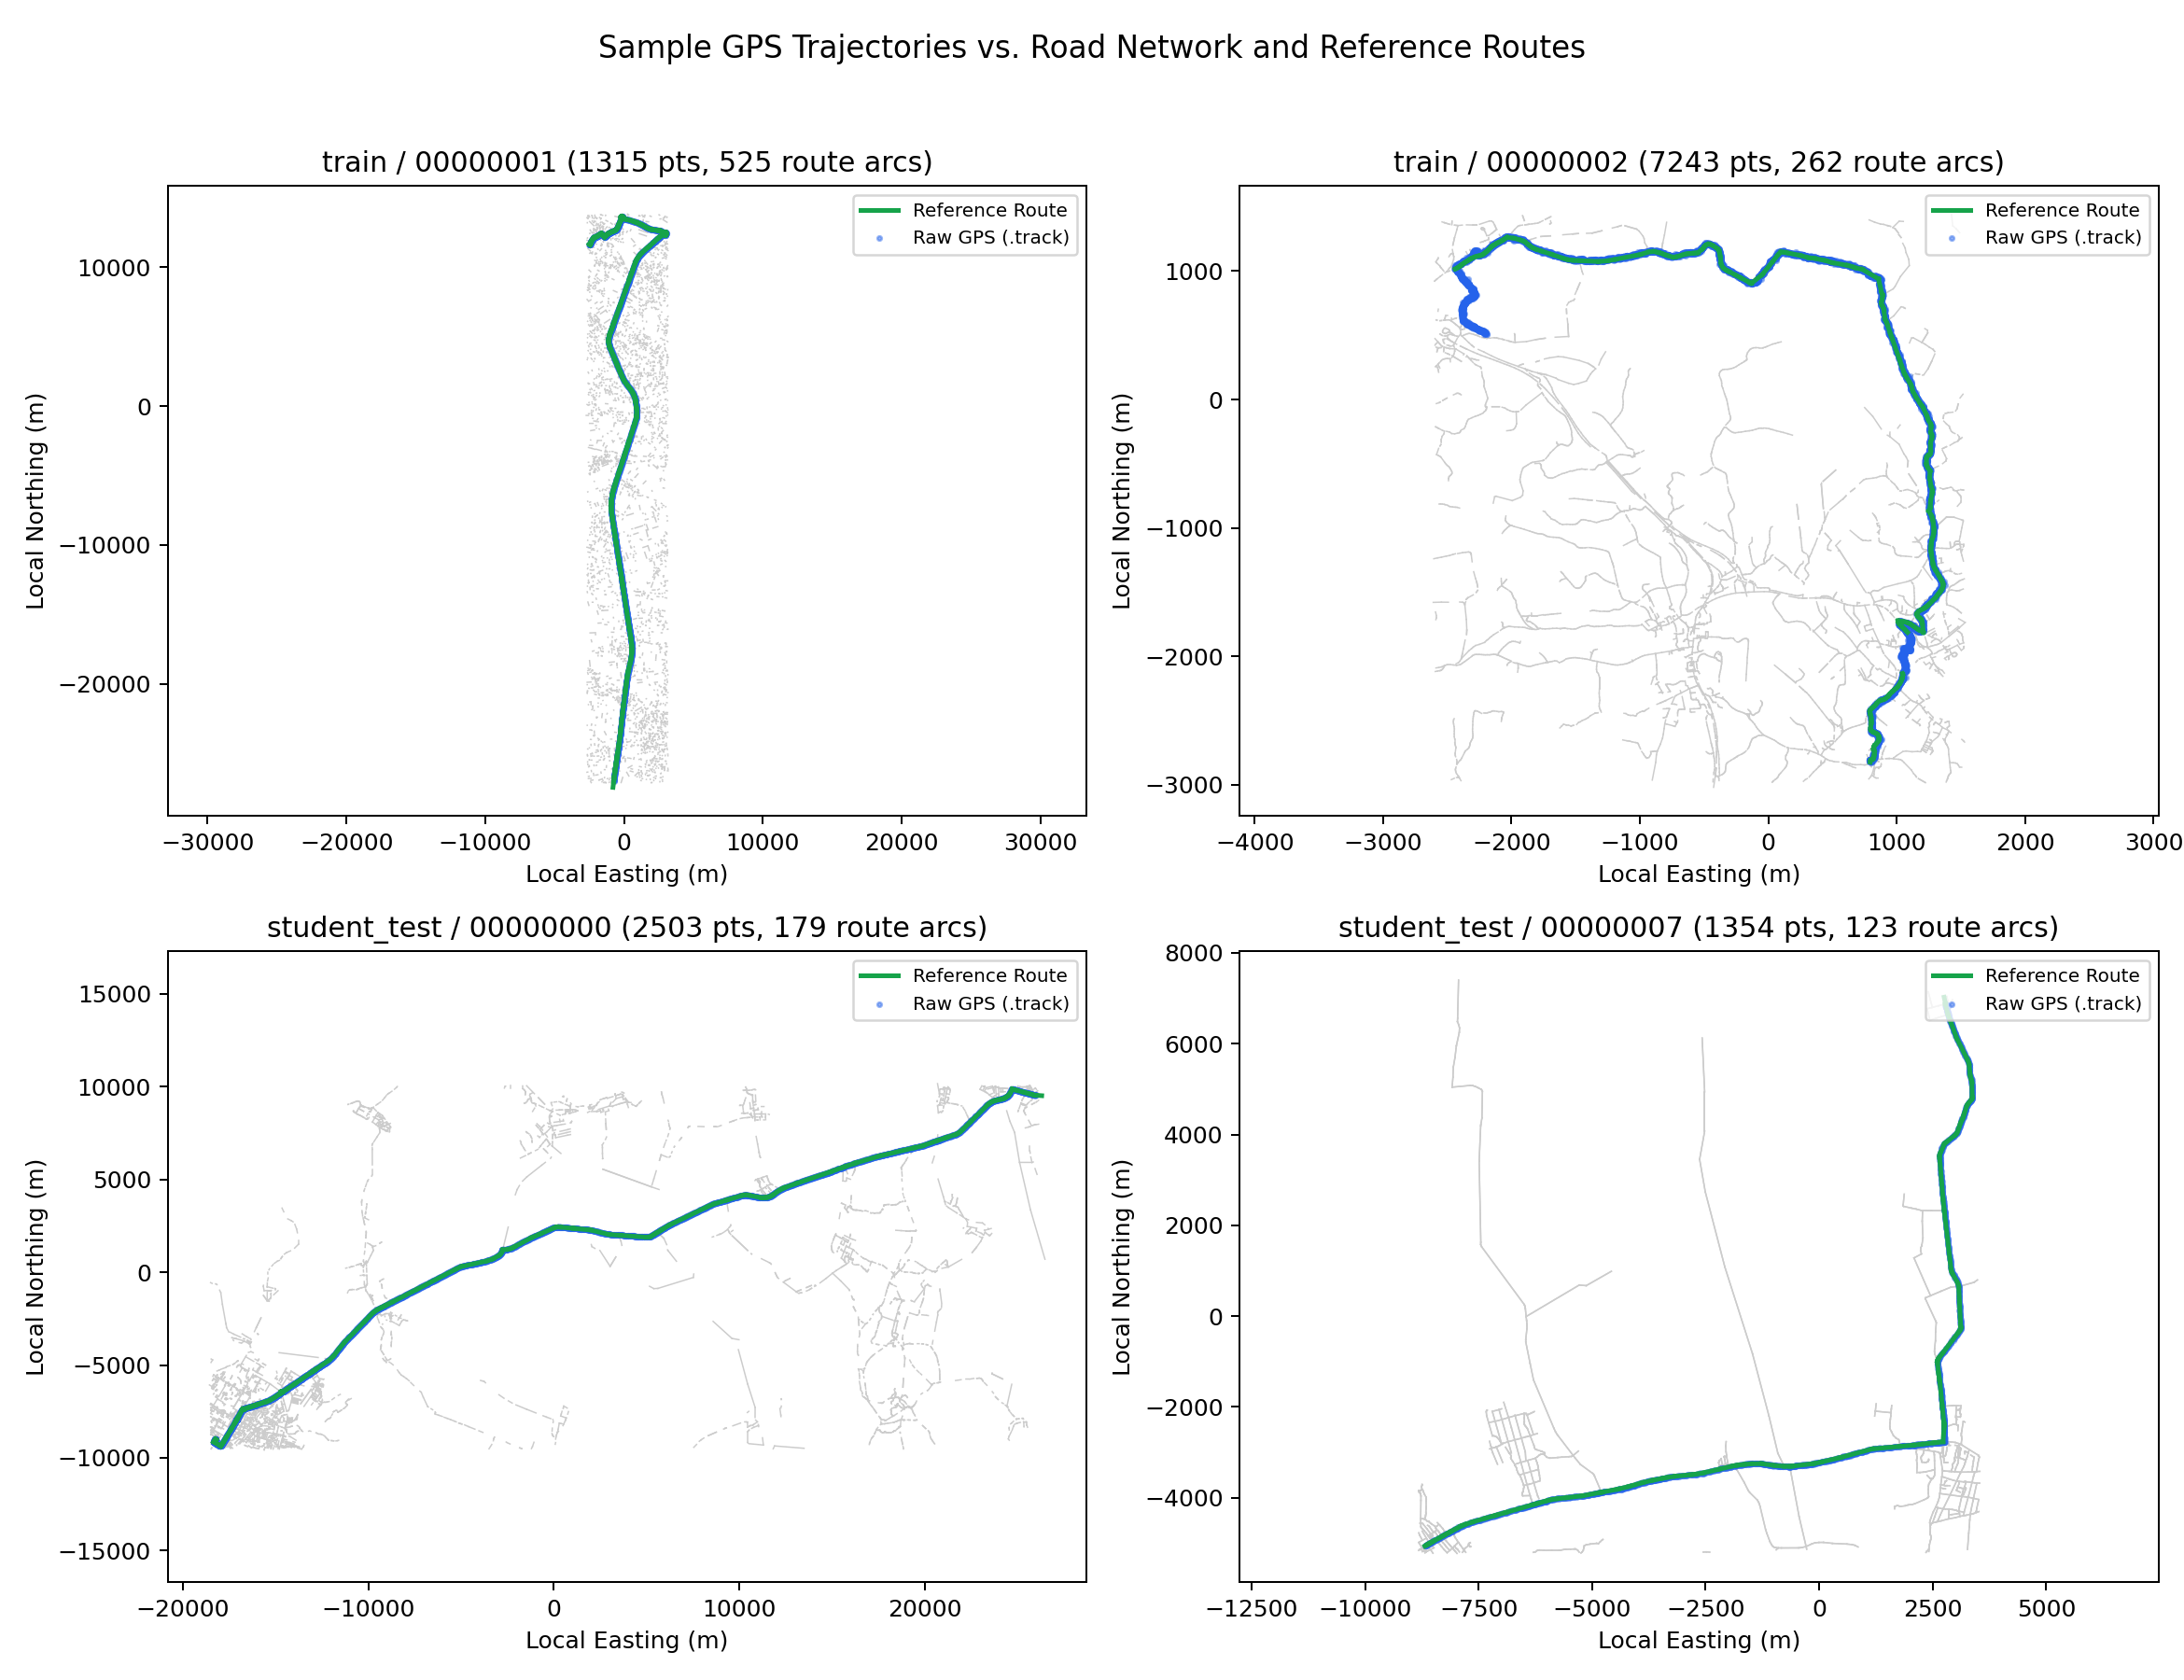

In [4]:
plot_files = [
    "01_trip_length_and_duration.png",
    "02_sampling_intervals_and_gaps.png",
    "03_road_network_and_gps_noise.png",
    "04_sample_trips_overlay.png",
]
for fname in plot_files:
    print("Plot:", fname)
    display(Image(filename=os.path.join(REPO_ROOT, "outputs", "eda", "plots", fname)))

In [5]:
maps_dir = os.path.join(REPO_ROOT, "outputs", "eda", "maps")
for mfile in sorted(os.listdir(maps_dir)):
    full_p = os.path.join(maps_dir, mfile)
    print(f"Folium map: {mfile} ({os.path.getsize(full_p) / 1024:.1f} KB)")

Folium map: eda_map_student_test_00000000.html (980.7 KB)
Folium map: eda_map_train_00000001.html (937.4 KB)


## 4. Candidate Generation, Feature Schema & Scaler Verification

{
  "candidate_k": 10,
  "pre_candidates_m": 100,
  "metadata_columns": [
    "trip_id",
    "obs_idx",
    "timestamp",
    "candidate_arc_id",
    "from_node",
    "to_node",
    "true_arc_id"
  ],
  "feature_columns": [
    "dist_to_arc_m",
    "dist_min_diff_m",
    "dist_ratio_to_min",
    "cand_rank",
    "proj_fraction",
    "dist_to_from_node_m",
    "dist_to_to_node_m",
    "arc_length_m",
    "heading_diff_rad",
    "heading_cos",
    "heading_sin",
    "gps_speed_mps",
    "dt_prev_s",
    "prev_gps_dist_to_arc_m",
    "next_gps_dist_to_arc_m",
    "is_connected_from_prev_top1"
  ],
  "target_column": "label",
  "scaler_path": "artifacts/feature_scaler.joblib",
  "scaler_fit_partition": "train_only",
  "train_filter": "removed off-route outlier points (>60m from reference route, e.g. parking/detour drift in 00000033 and 00000054)",
  "student_test_filter": "none (100% of observations retained)",
  "stats": {
    "train": {
      "n_trips": 80,
      "n_obs_raw": 208417,
    

student_test_candidates shape: (191600, 24)
NaNs in scaled test features: 0


,trip_id,obs_idx,timestamp,candidate_arc_id,from_node,to_node,true_arc_id,dist_to_arc_m,dist_min_diff_m,dist_ratio_to_min,...,arc_length_m,heading_diff_rad,heading_cos,heading_sin,gps_speed_mps,dt_prev_s,prev_gps_dist_to_arc_m,next_gps_dist_to_arc_m,is_connected_from_prev_top1,label
0,00000000,0,1.0,17634,8294,8293,17630,6.073164,0.000000,1.000000,...,358.455353,2.897776,-0.970424,-0.241408,23.6429,1.0,6.073164,0.365579,0.0,0
1,00000000,0,1.0,17630,8293,8294,17630,6.073164,0.000000,1.000000,...,358.455353,0.243816,0.970424,0.241408,23.6429,1.0,6.073164,0.365579,0.0,1
2,00000000,0,1.0,17635,8294,8307,17630,27.560242,21.487078,4.268909,...,262.007904,2.610690,-0.862350,0.506312,23.6429,1.0,27.560242,15.589555,0.0,0
3,00000000,0,1.0,17668,8307,8294,17630,27.560242,21.487078,4.268909,...,262.007904,0.530903,0.862350,-0.506312,23.6429,1.0,27.560242,15.589555,0.0,0
4,00000000,0,1.0,212,95,8294,17630,46.005936,39.932770,7.075122,...,33.196407,2.895811,-0.969947,-0.243315,23.6429,1.0,46.005936,22.662638,0.0,0
5,00000000,0,1.0,17633,8294,95,17630,46.005936,39.932770,7.075122,...,33.196407,0.245782,0.969947,0.243315,23.6429,1.0,46.005936,22.662638,0.0,0
6,00000000,0,1.0,17639,8296,95,17630,79.028358,72.955200,12.098948,...,69.739120,2.704577,-0.906019,-0.423238,23.6429,1.0,79.028358,55.856838,0.0,0
7,00000000,0,1.0,211,95,8296,17630,79.028358,72.955200,12.098948,...,69.739120,0.437016,0.906019,0.423238,23.6429,1.0,79.028358,55.856838,0.0,0
8,00000000,0,1.0,17651,8301,8314,17630,125.591637,119.518471,19.182793,...,257.790619,2.639181,-0.876424,0.481541,23.6429,1.0,125.591637,114.206619,0.0,0
9,00000000,0,1.0,17689,8314,8301,17630,125.591637,119.518471,19.182793,...,257.790619,0.502412,0.876424,-0.481541,23.6429,1.0,125.591637,114.206619,0.0,0


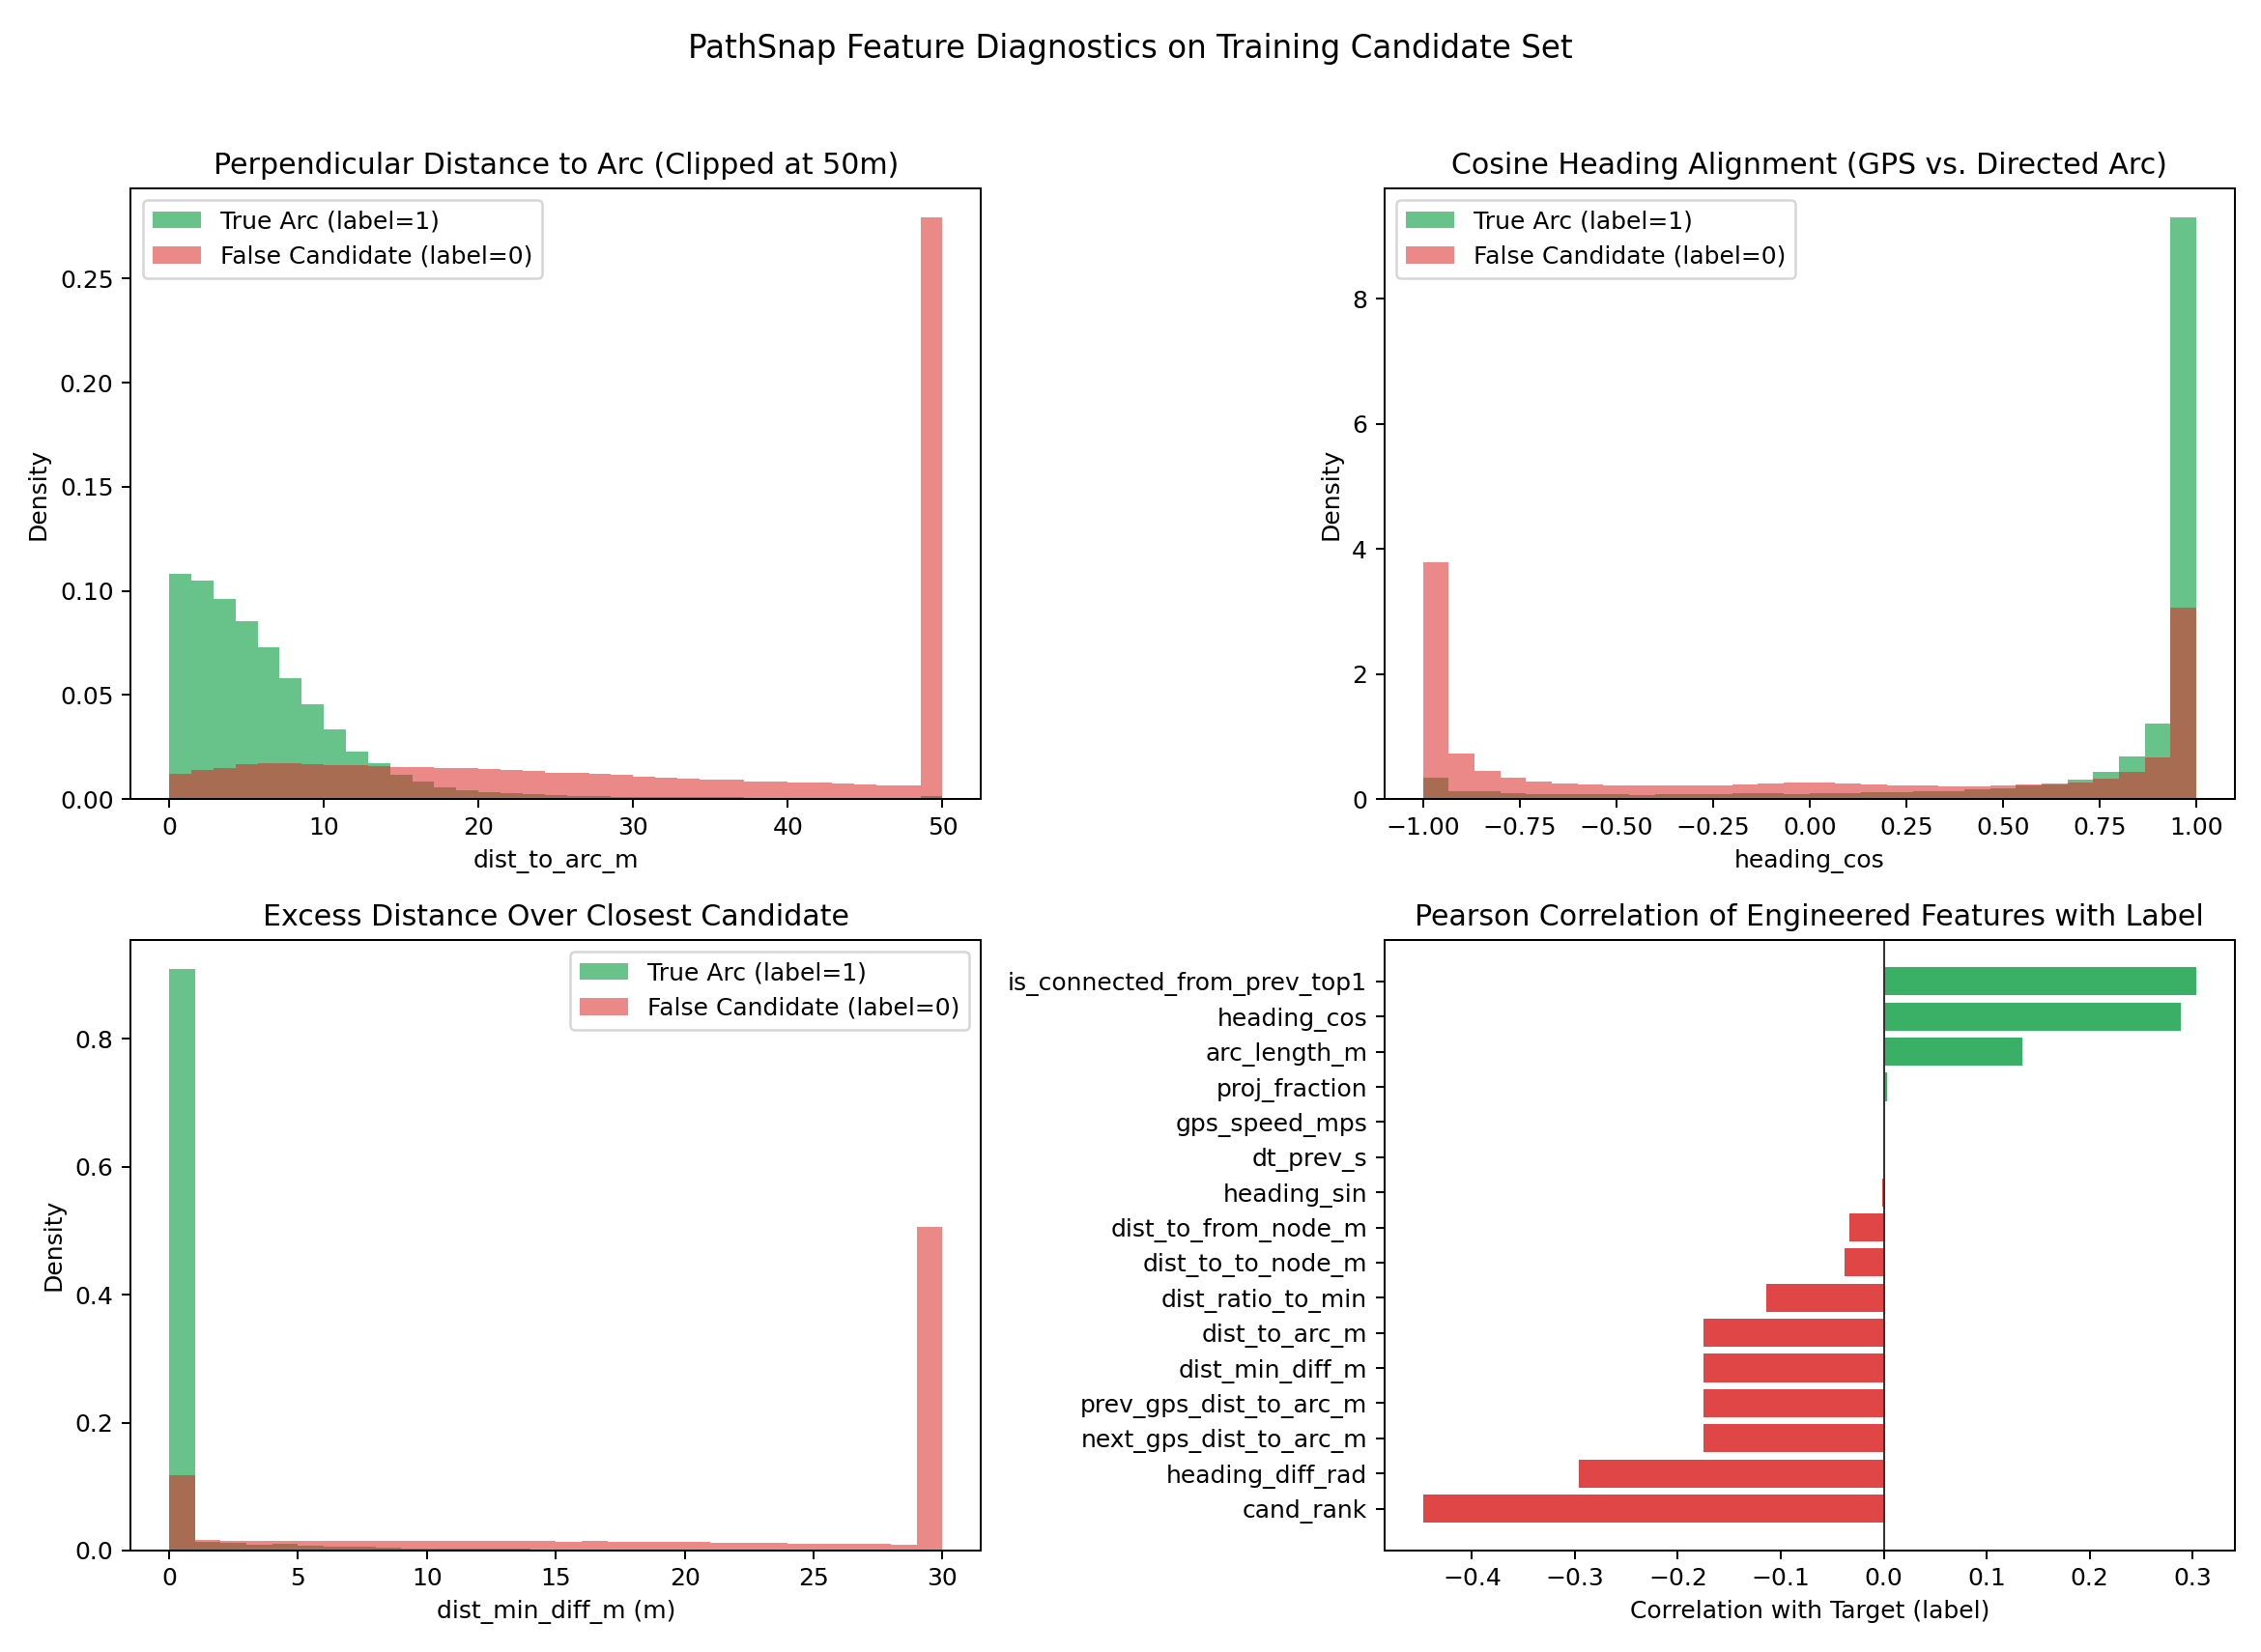

In [6]:
with open(os.path.join(REPO_ROOT, "artifacts", "feature_schema.json"), "r", encoding="utf-8") as f:
    schema = json.load(f)

print(json.dumps(schema, indent=2))

scaler = joblib.load(os.path.join(REPO_ROOT, "artifacts", "feature_scaler.joblib"))
test_df = joblib.load(os.path.join(REPO_ROOT, "data", "processed", "student_test_candidates.pkl"))
feat_cols = schema["feature_columns"]

X_test_scaled = scaler.transform(test_df[feat_cols].values)
print("student_test_candidates shape:", test_df.shape)
print("NaNs in scaled test features:", int(np.isnan(X_test_scaled).sum()))
display(test_df.head(10))

display(Image(filename=os.path.join(REPO_ROOT, "outputs", "eda", "plots", "05_feature_distributions_and_correlations.png")))